# 09.1 Sewing jobs and prices

**Issue #09, Pillar 3 (Who Actually Gets Paid).**

This notebook pulls three public US government series from FRED and puts them on one comparable scale:

| Series ID | What it measures | Role in the story |
|---|---|---|
| `CES3231500001` | Number of people employed in US apparel manufacturing (thousands, monthly) | The job that left |
| `CPIAPPSL` | Consumer price index for clothing | The price that stayed flat |
| `CPIAUCSL` | Consumer price index for everything | The backdrop: what other prices did |

**Question this notebook answers:** Since 1990, what happened to US sewing jobs, compared with what happened to clothing prices and prices in general?

**What it does not answer:** *Why?* Offshoring is one reason clothes stayed cheap, alongside machines, trade rules and fast-fashion business models. Nothing here proves cause.

## 1. Setup

Imports, file paths and the FRED key.

- The key is read from `.env` at the repo root (gitignored). It is never typed into this notebook.
- This notebook sits three folders deep (`notebooks/cycle 2/issue-09/`), so every path back to the repo root starts with `../../../`.

In [24]:
# --- Imports ---------------------------------------------------------------
import os                      # read the API key from the environment
from pathlib import Path       # build file paths that work on Windows and Mac

import requests                # call the FRED API
import pandas as pd            # tables and date handling
import matplotlib.pyplot as plt
from dotenv import load_dotenv # loads variables from the .env file

# --- Paths -----------------------------------------------------------------
# Repo root, relative to this notebook's folder.
ROOT = Path("../../..")

RAW_DIR = ROOT / "data" / "raw" / "cycle 2" / "issue-09"              # gitignored
PROCESSED_DIR = ROOT / "data" / "processed" / "cycle 2" / "issue-09"  # committed

# Create the data folders if this is the first run for the issue.
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# --- FRED key --------------------------------------------------------------
# load_dotenv reads ROOT/.env and puts FRED_API_KEY into the environment.
load_dotenv(ROOT / ".env")
FRED_API_KEY = os.getenv("FRED_API_KEY")

# Fail early with a clear message instead of a confusing API error later.
assert FRED_API_KEY, "FRED_API_KEY not found. Check the .env file at the repo root."


## 2. Extracting and analyzing data

### 2.1 Pull the three series from FRED

One small function fetches a series and returns it as a dated column of numbers.

Two FRED quirks are handled on purpose:

1. **Errors come back as normal-looking replies:** If a series ID is wrong, FRED still answers, but with an error message instead of data. The function checks for the `observations` field first and shows FRED's own message if it is missing.
2. **Missing months are sent as a dot (`"."`):** These are turned into blanks and dropped, so a gap in one series cannot break the maths.

All three pulls start at January 1990 because that is where the jobs series begins.

In [25]:
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"
START = "1990-01-01"   # first month available for the jobs series


def fetch_fred(series_id, start=START):
    """Fetch one FRED series and return it as a pandas Series indexed by date."""
    params = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": start,
    }
    resp = requests.get(FRED_URL, params=params, timeout=30)
    payload = resp.json()

    # FRED returns a JSON error object (not an HTTP error) on a bad request.
    # Show FRED's own message. The payload does not contain the API key.
    if "observations" not in payload:
        raise RuntimeError(f"FRED error for {series_id}: {payload}")

    df = pd.DataFrame(payload["observations"])[["date", "value"]]
    df["date"] = pd.to_datetime(df["date"])
    # FRED marks missing values with "."; coerce turns those into NaN.
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

    return df.dropna().set_index("date")["value"].rename(series_id)


# Series IDs and the plain-language column names used from here on.
SERIES = {
    "CES3231500001": "jobs_thousands",   # US apparel manufacturing jobs
    "CPIAPPSL": "clothing_prices",       # clothing price index
    "CPIAUCSL": "all_prices",            # all-items price index
}

# Fetch each series, then line them up side by side by month.
raw = pd.concat([fetch_fred(sid) for sid in SERIES], axis=1).rename(columns=SERIES)

# Save the untouched pull (gitignored) so the run can be traced later.
raw.to_csv(RAW_DIR / "9.1_fred_raw.csv")

raw.tail()

,jobs_thousands,clothing_prices,all_prices
date,,,
2026-05-01,72.8,137.069,333.979
2026-06-01,72.6,136.313,332.568
2026-07-01,72.2,136.434,332.813
2026-08-01,72.0,136.457,334.131
2026-09-01,71.4,NaN,NaN


### 2.2 Put all three on the same scale (January 1990 = 100)

Jobs are counted in thousands of people. Prices are index numbers. Plotted as they are, they would need two different vertical axes and two-axis charts are easy to misread. This is because the eye compares lines that are not on the same scale.

So each series is divided by its own January 1990 value and multiplied by 100. After that, every line starts at 100 and the reading is simple:

- **100** means "same as January 1990"
- **50** means "half of the 1990 level"
- **200** means "double the 1990 level"

Only months where all three series have a value are kept, so the "latest" point is the same month for every line.

In [26]:
BASE_DATE = pd.Timestamp("1990-01-01")

# Keep only months where all three series are present.
complete = raw.dropna()

# Divide every column by its January 1990 value, then scale to 100.
base = complete.loc[BASE_DATE]
indexed = (complete / base * 100).round(1)

# Save the processed table (committed) for the record.
indexed.to_csv(PROCESSED_DIR / "9.1_indexed_1990_100.csv")

indexed.tail()

,jobs_thousands,clothing_prices,all_prices
date,,,
2026-04-01,7.8,114.0,260.7
2026-05-01,7.8,114.3,261.9
2026-06-01,7.7,113.7,260.8
2026-07-01,7.7,113.8,261.0
2026-08-01,7.7,113.8,262.1


### 2.3 Headline numbers

The figures the slides and caption will draw on. Everything is calculated from the data above, nothing is typed in by hand.

**If any number here changes on a re-run, the Findings cell in section 5 must be updated by hand.**

In [27]:
first = complete.loc[BASE_DATE]   # January 1990 values
last = complete.iloc[-1]          # most recent month with all three series
latest_month = complete.index[-1].strftime("%B %Y")

# Jobs: start, end, and the percentage that disappeared.
jobs_start = first["jobs_thousands"]
jobs_now = last["jobs_thousands"]
jobs_lost_pct = (1 - jobs_now / jobs_start) * 100

# Prices: percentage change since January 1990.
clothing_change_pct = (last["clothing_prices"] / first["clothing_prices"] - 1) * 100
all_change_pct = (last["all_prices"] / first["all_prices"] - 1) * 100

# The single month when jobs were highest and lowest, as a sanity check.
jobs_peak_month = complete["jobs_thousands"].idxmax().strftime("%B %Y")
jobs_low_month = complete["jobs_thousands"].idxmin().strftime("%B %Y")

print(f"Latest month with all three series: {latest_month}")
print(f"Jobs, January 1990:  {jobs_start:,.1f} thousand")
print(f"Jobs, {latest_month}: {jobs_now:,.1f} thousand")
print(f"Share of jobs gone:  {jobs_lost_pct:.1f}%  (about {jobs_lost_pct / 10:.0f} in 10)")
print(f"Clothing prices since Jan 1990: {clothing_change_pct:+.1f}%")
print(f"All prices since Jan 1990:      {all_change_pct:+.1f}%")

# The 2000s on their own: January 2000 to January 2010.
jobs_2000 = complete.loc["2000-01-01", "jobs_thousands"]
jobs_2010 = complete.loc["2010-01-01", "jobs_thousands"]
lost_2000s_pct = (1 - jobs_2010 / jobs_2000) * 100

print(f"Jobs, Jan 2000: {jobs_2000:,.1f}k. Jan 2010: {jobs_2010:,.1f}k. Gone in the 2000s: {lost_2000s_pct:.1f}%")
print(f"Jobs highest in {jobs_peak_month}, lowest in {jobs_low_month}")

# Clothing vs. all prices at the end of the 2000s, on the 1990 = 100 scale.
clothing_2010 = indexed.loc["2010-01-01", "clothing_prices"]
all_2010 = indexed.loc["2010-01-01", "all_prices"]
print(f"Jan 2010, with Jan 1990 = 100: clothing {clothing_2010}, all prices {all_2010}")

Latest month with all three series: August 2026
Jobs, January 1990:  938.6 thousand
Jobs, August 2026: 72.0 thousand
Share of jobs gone:  92.3%  (about 9 in 10)
Clothing prices since Jan 1990: +13.8%
All prices since Jan 1990:      +162.1%
Jobs, Jan 2000: 504.0k. Jan 2010: 160.8k. Gone in the 2000s: 68.1%
Jobs highest in January 1990, lowest in April 2020
Jan 2010, with Jan 1990 = 100: clothing 100.0, all prices 170.6


### 2.4 Sparse sample for Canva

Canva charts are typed in by hand, so this exports a small table: January of every fifth year, plus the latest month.

Note for Canva: the last row is **not** a January and is **not** five years after the row before it. Label it with its real month so the axis is not misread (the Issue 7 chart lesson).

In [28]:
# January of every fifth year, starting 1990.
is_january = indexed.index.month == 1
# Every fifth year for the long view, plus every year of the 2000s,
# so the steepest decade is drawn in more detail.
is_fifth_year = indexed.index.year % 5 == 0
is_2000s = (indexed.index.year >= 2000) & (indexed.index.year <= 2010)
sparse = indexed[is_january & (is_fifth_year | is_2000s)].copy()

# Add the latest month if it is not already included.
if indexed.index[-1] not in sparse.index:
    sparse = pd.concat([sparse, indexed.iloc[[-1]]])

# Add the real job counts next to the index values, for the jobs-only chart.
sparse["jobs_thousands_actual"] = complete.loc[sparse.index, "jobs_thousands"]

# A readable label column for typing into Canva.
sparse.insert(0, "label", sparse.index.strftime("%b %Y"))

sparse.to_csv(PROCESSED_DIR / "9.1_canva_sparse.csv", index=False)
sparse

,label,jobs_thousands,clothing_prices,all_prices,jobs_thousands_actual
date,,,,,
1990-01-01,Jan 1990,100.0,100.0,100.0,938.6
1995-01-01,Jan 1995,88.0,110.3,118.0,826.2
2000-01-01,Jan 2000,53.7,109.0,132.8,504.0
2001-01-01,Jan 2001,48.6,107.9,137.7,456.6
2002-01-01,Jan 2002,39.0,103.8,139.4,365.6
2003-01-01,Jan 2003,34.8,101.8,143.2,327.0
2004-01-01,Jan 2004,30.6,100.2,146.1,287.0
2005-01-01,Jan 2005,28.1,100.3,150.3,264.2
2006-01-01,Jan 2006,25.5,99.2,156.3,239.3


## 3. Plot

Two exploratory charts for reading the shape of the data. Published charts are built in Canva from the sparse table exported in 3.4.

- **Chart A:** all three lines on the 1990 = 100 scale. Shows the gap opening up.
- **Chart B:** jobs alone, in actual numbers of people. Simpler, and keeps the new element in front.

The slide chart is chosen after looking at both. Clothing prices already appeared in Issues 1 and 6, so if Chart A reads as a price chart with a jobs line added, use Chart B.

### Chart A

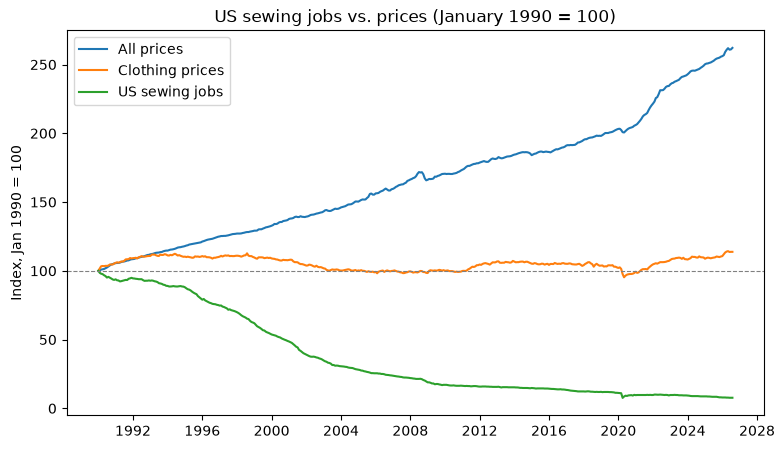

In [29]:
# Plain matplotlib, no styling. This is for reading the shape of the data.
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(indexed.index, indexed["all_prices"], label="All prices")
ax.plot(indexed.index, indexed["clothing_prices"], label="Clothing prices")
ax.plot(indexed.index, indexed["jobs_thousands"], label="US sewing jobs")

# Reference line at the 1990 starting level.
ax.axhline(100, linewidth=0.8, linestyle="--", color="grey")

ax.set_title("US sewing jobs vs. prices (January 1990 = 100)")
ax.set_ylabel("Index, Jan 1990 = 100")
ax.legend()
plt.show()

### 3.3 Chart B

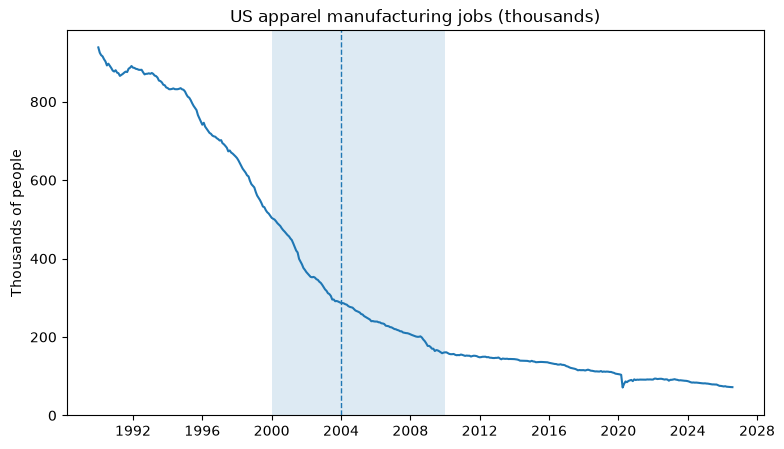

In [30]:
# Jobs alone, in actual thousands of people.
fig3, ax3 = plt.subplots(figsize=(9, 5))

ax3.plot(complete.index, complete["jobs_thousands"])

# The 2000s, and the month a famous jeans maker closed its last US plants.
ax3.axvspan(pd.Timestamp("2000-01-01"), pd.Timestamp("2010-01-01"), alpha=0.15)
ax3.axvline(pd.Timestamp("2004-01-01"), linestyle="--", linewidth=1)

ax3.set_title("US apparel manufacturing jobs (thousands)")
ax3.set_ylabel("Thousands of people")
ax3.set_ylim(bottom=0)   # start at zero so the size of the fall is honest
plt.show()

## 4. Findings

**Headline numbers**

- Latest month with all three series: August 2026.
- US apparel manufacturing jobs: 938.6 thousand in January 1990, 72.0 thousand in August 2026. About 9 in 10 gone (92.3%).
- The 2000s: 504.0 thousand in January 2000, 160.8 thousand in January 2010. About two in three gone in one decade (68.1%).
- Clothing prices rose 13.8% over the full period. Prices overall rose 162.1%.
- In plain terms: $100 of clothes in 1990 costs about $114 now. $100 of everyday goods in 1990 costs about $262 now. For every 100 sewing jobs in 1990, about 8 are left.

**Shape of the data**

- Jobs fell throughout the period. The fall was steepest in percentage terms in the 2000s, and largest in headcount in the 1990s (about 435 thousand lost, against about 343 thousand in the 2000s).
- The steepest stretch runs from about 1995 to 2003, so it starts before the 2000s. The 2000s are the decade that finished the decline, not the decade it began.
- The January 2004 plant closure used as this issue's example sits at the bend where the fall slows, consistent with that company being one of the last to leave.
- After 2010 the decline is slow. The lowest point on record is April 2020 (pandemic shutdowns), not today.
- Through the 2000s, clothing prices drifted back down to roughly their January 1990 level. They were below it in about a third of months, never by more than about 2% (lowest index value 98.2).
- By January 2010, clothing prices were back at their January 1990 level (index 100.0), while prices overall were about 71% higher (index 170.6).
- All three lines start together and fan apart: prices overall climb, clothing prices stay near their starting level, jobs fall.

**Charts chosen**

- Chart B (jobs alone) for THE STAT.
- Chart A (three lines) for THE SHIFT.
- Published versions are built in Canva from the sparse table exported in 2.4, then checked against the charts here.

**What this does and does not show**

- It shows that sewing jobs fell sharply while clothing prices rose a fraction as much as prices in general.
- It does not show that one caused the other. Offshoring is one reason among several, alongside machines, trade rules and fast-fashion business models.
- The jobs series counts everyone employed in apparel manufacturing, not only people at sewing machines.
- Price figures are averages across all clothing, not the price of any single item.
- September 2026 jobs data exists (71.4 thousand) but is left out, because price data for that month was not yet published.

**Does the pre-analysis thesis hold?**

Yes, with one refinement. Jobs fell by more than 90% while clothing prices barely moved against prices overall. The 2000s were the fastest decade of decline, which supports the 2000s setting, but the 1990s lost more jobs in absolute terms and the steep fall began around 1995.

**Sources**

- U.S. Bureau of Labor Statistics, All Employees, Apparel Manufacturing [CES3231500001], retrieved from FRED, Federal Reserve Bank of St. Louis.
- U.S. Bureau of Labor Statistics, Consumer Price Index for All Urban Consumers: Apparel in U.S. City Average [CPIAPPSL], retrieved from FRED, Federal Reserve Bank of St. Louis.
- U.S. Bureau of Labor Statistics, Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCSL], retrieved from FRED, Federal Reserve Bank of St. Louis.